# Jastrzębie-Zdrój: identyfikacja wzorców i anomalii w deformacjach terenu na podstawie danych EGMS

## Cel ćwiczenia

W ćwiczeniu analizujemy szeregi czasowe przemieszczeń punktów PS-InSAR pochodzących z danych EGMS. Celem jest rozpoznanie różnych sposobów zachowania punktów w czasie oraz wskazanie tych, których przebieg deformacji różni się od typowego zachowania obserwowanego w analizowanym zbiorze.

Analiza ma odpowiedzieć na dwa główne pytania:

1. **Które punkty PS wykazują nietypowe zachowanie deformacyjne?**
Do ich identyfikacji wykorzystamy metodę Isolation Forest, która pozwala wskazać obserwacje różniące się od większości punktów pod względem analizowanych cech szeregu czasowego.

2. **Jakie typowe wzorce zachowania występują wśród punktów PS?**
Za pomocą metody K-means pogrupujemy punkty o podobnych charakterystykach deformacji i porównamy przebieg ich szeregów czasowych.



EGMS: https://egms.land.copernicus.eu/

Budynki: https://eubucco.com/data/download/v0.2

Dokumentacja: https://land.copernicus.eu/en/products/european-ground-motion-service?tab=documentation

## Obszar badań

**Jastrzębie-Zdrój** leży w południowej części Górnośląskiego Zagłębia Węglowego. Pod miastem i w jego okolicy prowadzona jest eksploatacja węgla kamiennego (kopalnie Jastrzębskiej Spółki Węglowej, m.in. Borynia, Zofiówka, Bzie i Pniówek), dlatego spodziewamy się tu wyraźnych przemieszczeń terenu.

Analizowany fragment ma ok. 13,4 × 9,9 km (EPSG:2180: X 467,9–481,3 km, Y 227,8–237,7 km) i obejmuje 3977 punktów EGMS (marzec 2020 – grudzień 2024) oraz 26 847 budynków z bazy EUBUCCO.

# ETAP 1 — Import i kontrola danych (Jastrzębie-Zdrój)

Skrypt wymaga `pid`, `easting`, `northing`, prędkości, przyspieszenia, sezonowości, RMSE i dat obserwacji w kolumnach `YYYYMMDD`.
Sprawdź również, czy dane opisują przemieszczenia LOS, pionowe czy wschód–zachód: interpretacja znaków zależy od produktu EGMS.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [2]:
from pathlib import Path

# Ścieżki względne: notebook uruchamiamy z katalogu repozytorium
# (w Colabie: !git clone <adres repozytorium>, a potem %cd <nazwa katalogu>).
DATA_DIR = Path('.')
INPUT_CSV = DATA_DIR / 'dane' / 'Jastrzebie_zdroj_punkty.csv'
OUTPUT_CSV = DATA_DIR / 'EGMS_Jastrzebie_results.csv'
FIG_DIR = DATA_DIR / 'rysunki'
FIG_DIR.mkdir(exist_ok=True)

if not INPUT_CSV.is_file():
    raise FileNotFoundError(f'Nie znaleziono pliku: {INPUT_CSV.resolve()}')

df = pd.read_csv(INPUT_CSV, dtype={'pid': 'string'})

df = df.rename(columns={
    'height_ort': 'height_ortho',
    'mean_veloc': 'mean_velocity',
    'mean_vel_1': 'mean_velocity_std',
    'accelerati': 'acceleration',
    'accelera_1': 'acceleration_std',
    'seasonalit': 'seasonality',
    'seasonal_1': 'seasonality_std',
    'gnss_veloc': 'gnss_velocity_n',
    'gnss_vel_1': 'gnss_velocity_e',
    'gnss_vel_2': 'gnss_velocity_u'
})
if 'rmse_ts' not in df.columns and 'rmse' in df.columns:
    df = df.rename(columns={'rmse': 'rmse_ts'})

required = ['pid','easting','northing','mean_velocity','acceleration','seasonality','rmse_ts']
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f'Brak kolumn: {missing}. Sprawdź nazwy pól w CSV: {list(df.columns)[:30]}')

for c in ['easting','northing','mean_velocity','acceleration','seasonality','rmse_ts']:
    df[c] = pd.to_numeric(df[c], errors='coerce')
if df[['easting','northing']].isna().any().any():
    raise ValueError('Współrzędne easting/northing zawierają braki albo nie są liczbami.')
if df['pid'].isna().any() or df['pid'].duplicated().any():
    raise ValueError('Każdy PS powinien mieć niepusty, unikalny identyfikator pid.')
print('Liczba punktów PS:', len(df))
print('Liczba wszystkich kolumn:', len(df.columns))
display(df.head())

Liczba punktów PS: 3977
Liczba wszystkich kolumn: 253


,pid,easting,northing,height_ortho,rmse_ts,mean_velocity,mean_velocity_std,acceleration,acceleration_std,seasonality,...,20241013,20241019,20241025,20241031,20241106,20241112,20241118,20241124,20241130,20241206
0,30am6RkAU4,4939250.0,3015450.0,266.0,3.1,3.3,0.2,-4.20,0.23,1.1,...,12.9,14.2,14.8,15.7,16.5,17.0,17.5,18.2,18.8,17.6
1,30am6RkAUH,4940550.0,3015450.0,272.0,3.5,-6.6,0.2,-0.43,0.26,0.9,...,-23.4,-24.6,-25.2,-25.2,-25.7,-25.7,-27.8,-31.6,-33.1,-32.9
2,30am6RkAUh,4943150.0,3015450.0,256.0,3.6,-1.1,0.2,0.76,0.27,1.4,...,-8.9,-9.5,-9.6,-8.6,-8.2,-8.2,-9.1,-11.5,-11.8,-9.8
3,30amB8PPfO,4934650.0,3015550.0,236.0,3.2,-1.3,0.1,-0.05,0.23,0.8,...,-3.9,-3.0,-3.5,-4.7,-4.4,-3.4,-3.1,-3.2,-5.5,-7.9
4,30amB8PPfc,4936050.0,3015550.0,266.0,4.5,-0.5,0.2,-2.35,0.33,1.1,...,-3.9,-6.6,-8.2,-10.3,-11.5,-10.5,-9.4,-8.0,-6.8,-6.8


In [3]:
date_cols = sorted([
    col for col in df.columns
    if str(col).isdigit() and len(str(col)) == 8
])
if len(date_cols) < 6:
    raise ValueError('Za mało kolumn dat YYYYMMDD. Upewnij się, że CSV zawiera szeregi czasowe EGMS.')
dates = pd.to_datetime(date_cols, format='%Y%m%d', errors='raise')
df[date_cols] = df[date_cols].apply(pd.to_numeric, errors='coerce')

print('Liczba punktów PS:', len(df))
print('Liczba obserwacji czasowych:', len(date_cols))
print('Pierwsza obserwacja:', dates.min().date())
print('Ostatnia obserwacja:', dates.max().date())
print('Braki w szeregu czasowym:', int(df[date_cols].isna().sum().sum()))
print('Punkty z brakami:', int(df[date_cols].isna().any(axis=1).sum()))

Liczba punktów PS: 3977
Liczba obserwacji czasowych: 239
Pierwsza obserwacja: 2020-03-08
Ostatnia obserwacja: 2024-12-06
Braki w szeregu czasowym: 0
Punkty z brakami: 0


## Podstawowe parametry EGMS

Przegląd parametrów dostarczonych wraz z danymi. Szczególnie ważne są:

- `mean_velocity` — średnia prędkość przemieszczenia,
- `acceleration` — informacja o zmianie prędkości,
- `seasonality` — amplituda zachowania sezonowego,
- `rmse_ts` — parametr jakości/rozrzutu dopasowania szeregu.



In [4]:
basic_features = ["mean_velocity", "acceleration", "seasonality", "rmse_ts"]
df[basic_features].describe().T.round(3)


,count,mean,std,min,25%,50%,75%,max
mean_velocity,3977.0,-0.549,7.764,-37.0,-4.00,-0.1,2.20,37.40
acceleration,3977.0,0.016,0.849,-4.6,-0.29,0.0,0.32,5.11
seasonality,3977.0,0.686,0.550,0.0,0.30,0.5,0.90,4.30
rmse_ts,3977.0,1.472,0.825,0.4,0.80,1.2,1.90,4.50


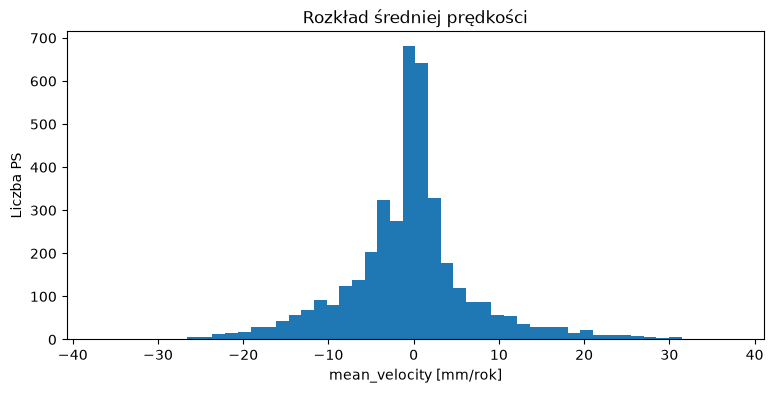

In [5]:
plt.figure(figsize=(9, 4))
plt.hist(df["mean_velocity"], bins=50)
plt.xlabel("mean_velocity [mm/rok]")
plt.ylabel("Liczba PS")
plt.title("Rozkład średniej prędkości")
plt.show()


## Jaki produkt EGMS analizujemy?

Interpretacja znaku przemieszczeń zależy od produktu EGMS. Sprawdzamy rozstaw punktów (EGMS Ortho to regularna siatka 100 m) i rozkład `mean_velocity`.

In [6]:
# EGMS Ortho (L3) to siatka 100 m z dwiema składowymi: pionową (U) i poziomą wschód–zachód (E).
from scipy.spatial import cKDTree

xy = df[['easting', 'northing']].to_numpy()
nn_dist, _ = cKDTree(xy).query(xy, k=2)
print('Mediana odległości do najbliższego PS [m]:', np.median(nn_dist[:, 1]))
print('Udział PS z mean_velocity > 0:', round((df['mean_velocity'] > 0).mean() * 100, 1), '%')
print('Kwantyle mean_velocity [mm/rok]:')
print(df['mean_velocity'].quantile([0.01, 0.05, 0.5, 0.95, 0.99]).round(1).to_string())

Mediana odległości do najbliższego PS [m]: 100.0
Udział PS z mean_velocity > 0: 48.2 %
Kwantyle mean_velocity [mm/rok]:
0.01   -21.1
0.05   -13.7
0.50    -0.1
0.95    13.0
0.99    23.6


**Wniosek.** Punkty leżą w regularnej siatce co 100 m, więc są to dane **EGMS Ortho (L3)**. Rozkład prędkości jest prawie symetryczny wokół zera (48% PS ma prędkość dodatnią; mediana −0,1 mm/rok; kwantyle 1% i 99%: −21 i +24 mm/rok), a na mapie (ETAP 6) strefy dodatnie i ujemne występują parami po obu stronach obszarów bez PS. Taki obraz odpowiada **składowej poziomej wschód–zachód (E)**: wartość dodatnia oznacza ruch na wschód, ujemna — ruch na zachód. W składowej pionowej w rejonie górniczym zdecydowanie przeważałyby wartości ujemne (osiadanie).

> Potwierdza to nazwa pobranego pliku: `EGMS_L3_E49N30_100km_E_2020_2024_1.zip` (`_E_` = składowa wschód–zachód).

## Oglądanie pojedynczego szeregu czasowego

Funkcja `plot_ps()` będzie również używana później do kontroli punktów wskazanych przez model.


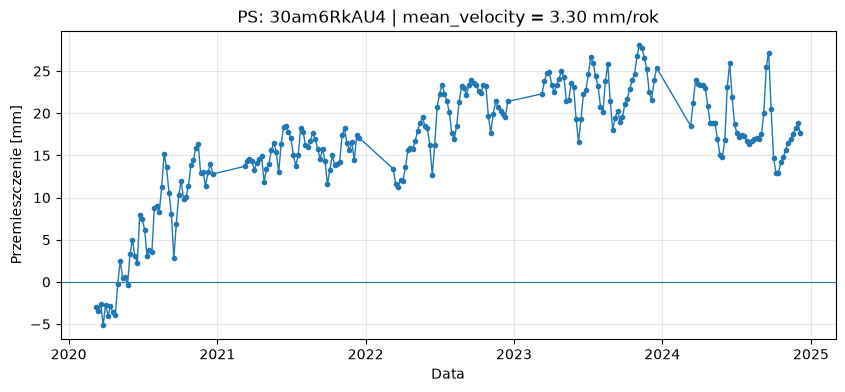

In [7]:
def plot_ps(pid):
    row = df[df["pid"] == pid].iloc[0]
    y = row[date_cols].astype(float).values

    plt.figure(figsize=(10, 4))
    plt.plot(dates, y, marker=".", linewidth=1)
    plt.axhline(0, linewidth=0.8)
    plt.xlabel("Data")
    plt.ylabel("Przemieszczenie [mm]")
    plt.title(
        f"PS: {pid} | mean_velocity = {row['mean_velocity']:.2f} mm/rok"
    )
    plt.grid(alpha=0.3)
    plt.show()

plot_ps(df.iloc[0]["pid"])


# ETAP 2 — Zamiana szeregu czasowego na informacje

Model nie otrzymuje całego szeregu 239 obserwacji bezpośrednio. Najpierw musimy stworzyć kilka **interpretowalnych cech**, które opisują zachowanie punktu PS. W ML nazywamy to **feature engineeringiem**.


In [8]:
# Rzeczywisty czas w latach od pierwszej obserwacji.
# Dzięki temu regresja uwzględnia faktyczne odstępy między datami.
time_years = ((dates - dates.min()).days / 365.25).to_numpy()

# Tworzymy funkcję do wyznaczania trendu liniowego dla dowolnego fragmentu szeregu czasowego.
# Nachylenie trendu (slope) jest wyrażone w mm/rok. Dla całego szeregu opisuje długookresowe tempo
# zmian i może być zbliżone do mean_velocity dostarczonego przez EGMS. Funkcja będzie jednak
# potrzebna przede wszystkim do porównywania trendów wyznaczonych dla różnych okresów oraz do oceny
# ich regularności za pomocą R².

def fit_linear_trend(values, time_values):
    y = np.asarray(values, dtype=float)
    t = np.asarray(time_values, dtype=float)

    mask = np.isfinite(y) & np.isfinite(t)
    y = y[mask]
    t = t[mask]

    if len(y) < 3 or np.unique(t).size < 2:
        return np.nan, np.nan

    model = LinearRegression()
    model.fit(t.reshape(-1, 1), y)

    slope = model.coef_[0]
    r2 = model.score(t.reshape(-1, 1), y)

    return slope, r2

## 2A. Trend całego okresu

`trend` jest nachyleniem regresji liniowej dopasowanej do **wszystkich obserwacji** punktu PS i ma jednostkę mm/rok.

`trend_R2` informuje, jak dobrze prosty trend liniowy opisuje cały przebieg. Niskie `R²` nie oznacza automatycznie błędnych danych — przebieg może być nieliniowy lub zmienny w czasie.


In [9]:
global_results = df.apply(
    lambda row: fit_linear_trend(row[date_cols].values, time_years),
    axis=1
)

df["trend"] = [x[0] for x in global_results]
df["trend_R2"] = [x[1] for x in global_results]

df[["pid", "mean_velocity", "trend", "trend_R2"]].head()


C:\Users\hubi7\AppData\Local\Temp\ipykernel_31040\2363804231.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["trend"] = [x[0] for x in global_results]
C:\Users\hubi7\AppData\Local\Temp\ipykernel_31040\2363804231.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["trend_R2"] = [x[1] for x in global_results]


,pid,mean_velocity,trend,trend_R2
0,30am6RkAU4,3.3,3.419221,0.496334
1,30am6RkAUH,-6.6,-6.474814,0.864422
2,30am6RkAUh,-1.1,-1.050730,0.128800
3,30amB8PPfO,-1.3,-1.273509,0.237754
4,30amB8PPfc,-0.5,-0.553325,0.023410


In [10]:
correlation = df["trend"].corr(
    df["mean_velocity"]
)

print(
    "Korelacja trend vs mean_velocity:",
    round(correlation, 3)
)

Korelacja trend vs mean_velocity: 1.0


## 2B. Trendy w kolejnych latach

Dla każdego roku dopasowujemy osobną prostą do wszystkich obserwacji z tego roku. Nie interesuje nas pojedynczy skok, lecz **tempo zmian w dłuższym fragmencie szeregu**.


In [11]:
years = sorted(pd.Index(dates.year).unique())
yearly_trend_cols = []

for year in years:
    mask = dates.year == year
    cols_year = [col for col, keep in zip(date_cols, mask) if keep]
    dates_year = dates[mask]
    time_year = ((dates_year - dates_year.min()).days / 365.25).to_numpy()

    col_name = f"trend_{year}"
    yearly_trend_cols.append(col_name)

    df[col_name] = df.apply(
        lambda row: fit_linear_trend(row[cols_year].values, time_year)[0],
        axis=1
    )

print("Analizowane lata:", years)
df[["pid"] + yearly_trend_cols].head()


C:\Users\hubi7\AppData\Local\Temp\ipykernel_31040\666787241.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[col_name] = df.apply(


C:\Users\hubi7\AppData\Local\Temp\ipykernel_31040\666787241.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[col_name] = df.apply(


C:\Users\hubi7\AppData\Local\Temp\ipykernel_31040\666787241.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[col_name] = df.apply(


C:\Users\hubi7\AppData\Local\Temp\ipykernel_31040\666787241.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[col_name] = df.apply(


Analizowane lata: [2020, 2021, 2022, 2023, 2024]


C:\Users\hubi7\AppData\Local\Temp\ipykernel_31040\666787241.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[col_name] = df.apply(


,pid,trend_2020,trend_2021,trend_2022,trend_2023,trend_2024
0,30am6RkAU4,25.033912,2.099104,11.422323,1.358982,-6.582309
1,30am6RkAUH,-1.051026,-4.787001,-3.361936,-0.479757,-11.213539
2,30am6RkAUh,-1.751088,6.501506,6.352820,-5.126664,-2.430495
3,30amB8PPfO,1.025557,5.745524,-4.903636,-2.577539,6.788417
4,30amB8PPfc,8.995213,-3.958659,-7.324560,-4.890419,-18.569972


### Ewolucja trendów rocznych

Z pięciu trendów rocznych tworzymy jedną prostą cechę: `annual_trend_slope`.

- wartość **ujemna**: trendy roczne stają się z czasem bardziej ujemne,
- wartość **dodatnia**: trendy roczne przesuwają się w stronę bardziej dodatnich wartości,
- wartość bliska **0**: brak wyraźnego kierunku zmian między latami.

Dodatkowo liczymy `annual_trend_R2` jako cechę diagnostyczną: pokazuje, czy zmiana trendów rocznych jest systematyczna.

In [12]:
### Zmienność rocznych trendów

# Dla każdego punktu PS obliczono odchylenie standardowe rocznych prędkości przemieszczenia. Parametr `annual_trend_std` opisuje, jak silnie różniły się prędkości wyznaczone w kolejnych latach.
# Niska wartość oznacza podobne tempo przemieszczeń w kolejnych latach, natomiast wysoka wartość wskazuje na większą zmienność
# międzyroczną lub wystąpienie roku wyraźnie różniącego się od pozostałych.

df["annual_trend_std"] = (
    df[yearly_trend_cols]
    .std(axis=1)
)

df[
    ["pid"]
    + yearly_trend_cols
    + ["annual_trend_std"]
].head()

C:\Users\hubi7\AppData\Local\Temp\ipykernel_31040\3718786268.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["annual_trend_std"] = (


,pid,trend_2020,trend_2021,trend_2022,trend_2023,trend_2024,annual_trend_std
0,30am6RkAU4,25.033912,2.099104,11.422323,1.358982,-6.582309,12.088646
1,30am6RkAUH,-1.051026,-4.787001,-3.361936,-0.479757,-11.213539,4.300890
2,30am6RkAUh,-1.751088,6.501506,6.352820,-5.126664,-2.430495,5.370504
3,30amB8PPfO,1.025557,5.745524,-4.903636,-2.577539,6.788417,5.085410
4,30amB8PPfc,8.995213,-3.958659,-7.324560,-4.890419,-18.569972,9.828506


## 2C. Ostatnie 12 miesięcy względem wcześniejszego okresu

Sprawdzamy, czy zachowanie punktu PS w ostatnich 12 miesiącach różniło się od jego wcześniejszego, długoterminowego zachowania.

`baseline_velocity` jest trendem dopasowanym do wszystkich obserwacji wcześniejszych niż ostatnie 12 miesięcy.

`recent_velocity` jest trendem dopasowanym do obserwacji z ostatnich 12 miesięcy.

Zmianę trendu obliczamy jako:

`trend_change = recent_velocity - baseline_velocity`

Wartość ujemna oznacza, że trend w ostatnich 12 miesiącach stał się bardziej ujemny. Wartość dodatnia oznacza, że trend stał się mniej ujemny lub bardziej dodatni.


In [13]:
last_date = dates.max()
recent_start = last_date - pd.DateOffset(years=1)
baseline_mask = dates < recent_start
recent_mask = dates >= recent_start
baseline_cols = [col for col, keep in zip(date_cols, baseline_mask) if keep]
recent_cols = [col for col, keep in zip(date_cols, recent_mask) if keep]
if len(baseline_cols) < 3 or len(recent_cols) < 3:
    raise ValueError('Potrzebne >=3 daty w okresie bazowym i ostatnich 12 miesiącach.')
baseline_dates, recent_dates = dates[baseline_mask], dates[recent_mask]
baseline_time = ((baseline_dates - baseline_dates.min()).days / 365.25).to_numpy()
recent_time = ((recent_dates - recent_dates.min()).days / 365.25).to_numpy()

df['baseline_velocity'] = df.apply(
    lambda row: fit_linear_trend(row[baseline_cols].values, baseline_time)[0], axis=1)
df['recent_velocity'] = df.apply(
    lambda row: fit_linear_trend(row[recent_cols].values, recent_time)[0], axis=1)
df['trend_change'] = df['recent_velocity'] - df['baseline_velocity']
print('Okres bazowy:', baseline_dates.min().date(), '–', baseline_dates.max().date())
print('Okres ostatni:', recent_dates.min().date(), '–', recent_dates.max().date())
display(df[['pid','baseline_velocity','recent_velocity','trend_change']].head())

C:\Users\hubi7\AppData\Local\Temp\ipykernel_31040\474474661.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['baseline_velocity'] = df.apply(


Okres bazowy: 2020-03-08 – 2023-11-30
Okres ostatni: 2023-12-06 – 2024-12-06


C:\Users\hubi7\AppData\Local\Temp\ipykernel_31040\474474661.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['recent_velocity'] = df.apply(
C:\Users\hubi7\AppData\Local\Temp\ipykernel_31040\474474661.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['trend_change'] = df['recent_velocity'] - df['baseline_velocity']


,pid,baseline_velocity,recent_velocity,trend_change
0,30am6RkAU4,5.673366,-7.040426,-12.713791
1,30am6RkAUH,-6.661497,-7.572454,-0.910958
2,30am6RkAUh,-0.974954,3.044110,4.019065
3,30amB8PPfO,-1.015304,4.949982,5.965286
4,30amB8PPfc,0.626706,-19.989492,-20.616198


# ETAP 3 — Wybór cech

Wykorzystujemy trzy parametry: `mean_velocity`, `acceleration`, `trend_change`.
`rmse_ts`, `trend_R2` i `seasonality` zachowujemy do diagnostyki; duży wynik anomalii **nie oznacza automatycznie uszkodzonego budynku ani osiadania terenu**.
W razie braków cech punkty będą wyłączone z modelowania i oznaczone polem `analysis_valid = False`.

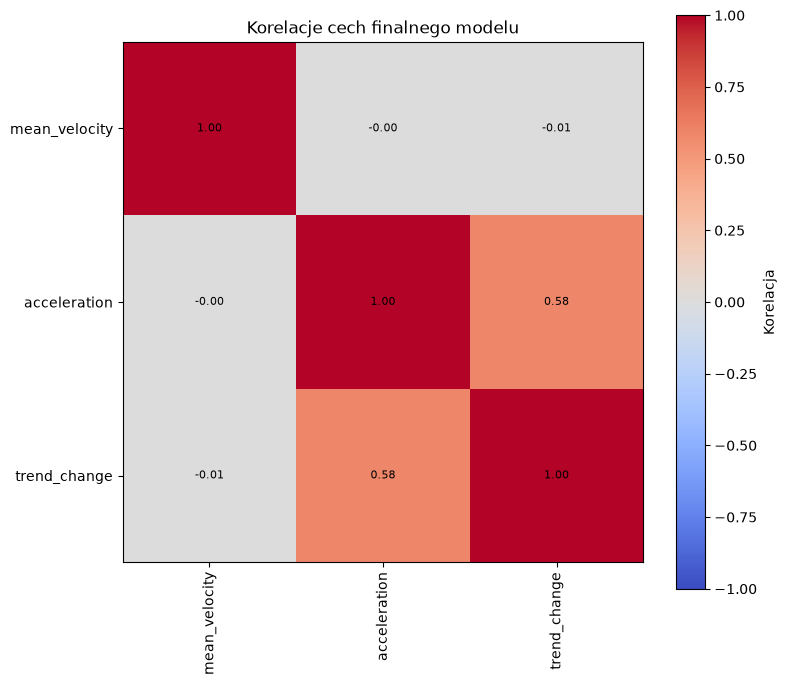

In [14]:
model_features = [
    "mean_velocity",
    "acceleration",
    "trend_change"
]

control_features = [
    "rmse_ts",
    "trend_R2",
    "seasonality"
]

corr_features = model_features
corr = df[corr_features].corr()

plt.figure(figsize=(8, 7))
plt.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
plt.colorbar(label="Korelacja")

plt.xticks(range(len(corr_features)), corr_features, rotation=90)
plt.yticks(range(len(corr_features)), corr_features)

for i in range(len(corr_features)):
    for j in range(len(corr_features)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}",
                 ha="center", va="center", fontsize=8)

plt.title("Korelacje cech finalnego modelu")
plt.tight_layout()
plt.show()


# ETAP 4 — Isolation Forest: wykrywanie nietypowych PS

Isolation Forest jest metodą **uczenia nienadzorowanego**. Nie mamy etykiet „uszkodzony / nieuszkodzony”, dlatego model nie uczy się uszkodzeń.

Model odpowiada na pytanie:

> **Które PS mają nietypową kombinację cech deformacyjnych na tle całego zbioru?**

`anomaly_score` traktujemy jako wynik ciągły: im wyższy, tym bardziej nietypowy punkt.


In [15]:
# Isolation Forest działa na cechach bez standaryzacji (model drzewiasty).
mask_model = df[model_features].replace([np.inf,-np.inf], np.nan).notna().all(axis=1)
df['analysis_valid'] = mask_model
X_if = df.loc[mask_model, model_features].copy()
if len(X_if) < 10:
    raise ValueError(f'Za mało punktów z kompletem cech: {len(X_if)}')

iso_forest = IsolationForest(n_estimators=300, contamination='auto', random_state=42)
iso_forest.fit(X_if)
df['anomaly_score'] = np.nan
df.loc[mask_model, 'anomaly_score'] = -iso_forest.score_samples(X_if)
print('Punkty wykorzystane w modelach:', int(mask_model.sum()))
print('Punkty pominięte przez braki:', int((~mask_model).sum()))

C:\Users\hubi7\AppData\Local\Temp\ipykernel_31040\3904379808.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['analysis_valid'] = mask_model


Punkty wykorzystane w modelach: 3977
Punkty pominięte przez braki: 0


C:\Users\hubi7\AppData\Local\Temp\ipykernel_31040\3904379808.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['anomaly_score'] = np.nan


Za anomalne przyjmujemy umownie 5% PS o najwyższym anomaly_score. Nie oznacza to, że 5% punktów reprezentuje rzeczywistą anomalną deformację, jest to próg służący do wyboru punktów do dalszej analizy.

In [16]:
threshold = df.loc[mask_model, 'anomaly_score'].quantile(0.95)
# Około 5% najwyżej ocenionych punktów, arbitralny próg do analizy (nie walidacja zagrożenia).
df['anomaly'] = df['anomaly_score'].ge(threshold).fillna(False)
print('Próg anomaly_score:', round(threshold, 3))
print(df['anomaly'].value_counts())

Próg anomaly_score: 0.594
anomaly
False    3778
True      199
Name: count, dtype: int64


C:\Users\hubi7\AppData\Local\Temp\ipykernel_31040\1727939930.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['anomaly'] = df['anomaly_score'].ge(threshold).fillna(False)


## Kontrola wyniku

Isolation Forest wskazuje punkty nietypowe na podstawie kombinacji analizowanych cech. Sam wysoki anomaly_score nie oznacza jednak automatycznie anomalnej deformacji. Dlatego sprawdzimy:
1. Czy anomaly_score jest związany z RMSE szeregu czasowego?
2. Jak wyglądają rzeczywiste szeregi czasowe punktów o najwyższym anomaly_score?
3. Czy model wskazuje wyłącznie PS o najbardziej ujemnym mean_velocity?

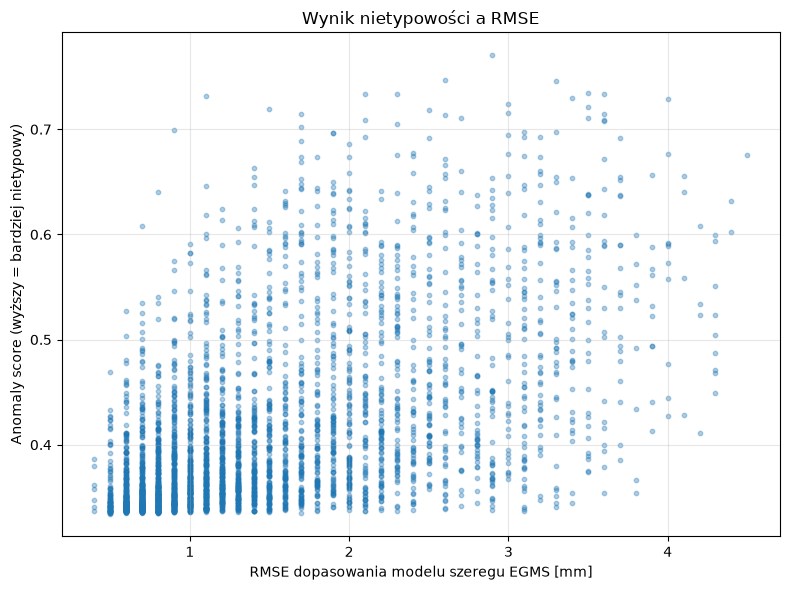

In [17]:
plt.figure(figsize=(8, 6))
plt.scatter(df['rmse_ts'], df['anomaly_score'], alpha=0.35, s=10)
plt.xlabel('RMSE dopasowania modelu szeregu EGMS [mm]')
plt.ylabel('Anomaly score (wyższy = bardziej nietypowy)')
plt.title('Wynik nietypowości a RMSE')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
corr_rmse = df["anomaly_score"].corr(df["rmse_ts"])

print("Korelacja anomaly_score vs RMSE:",
      round(corr_rmse, 3))

Korelacja anomaly_score vs RMSE: 0.558


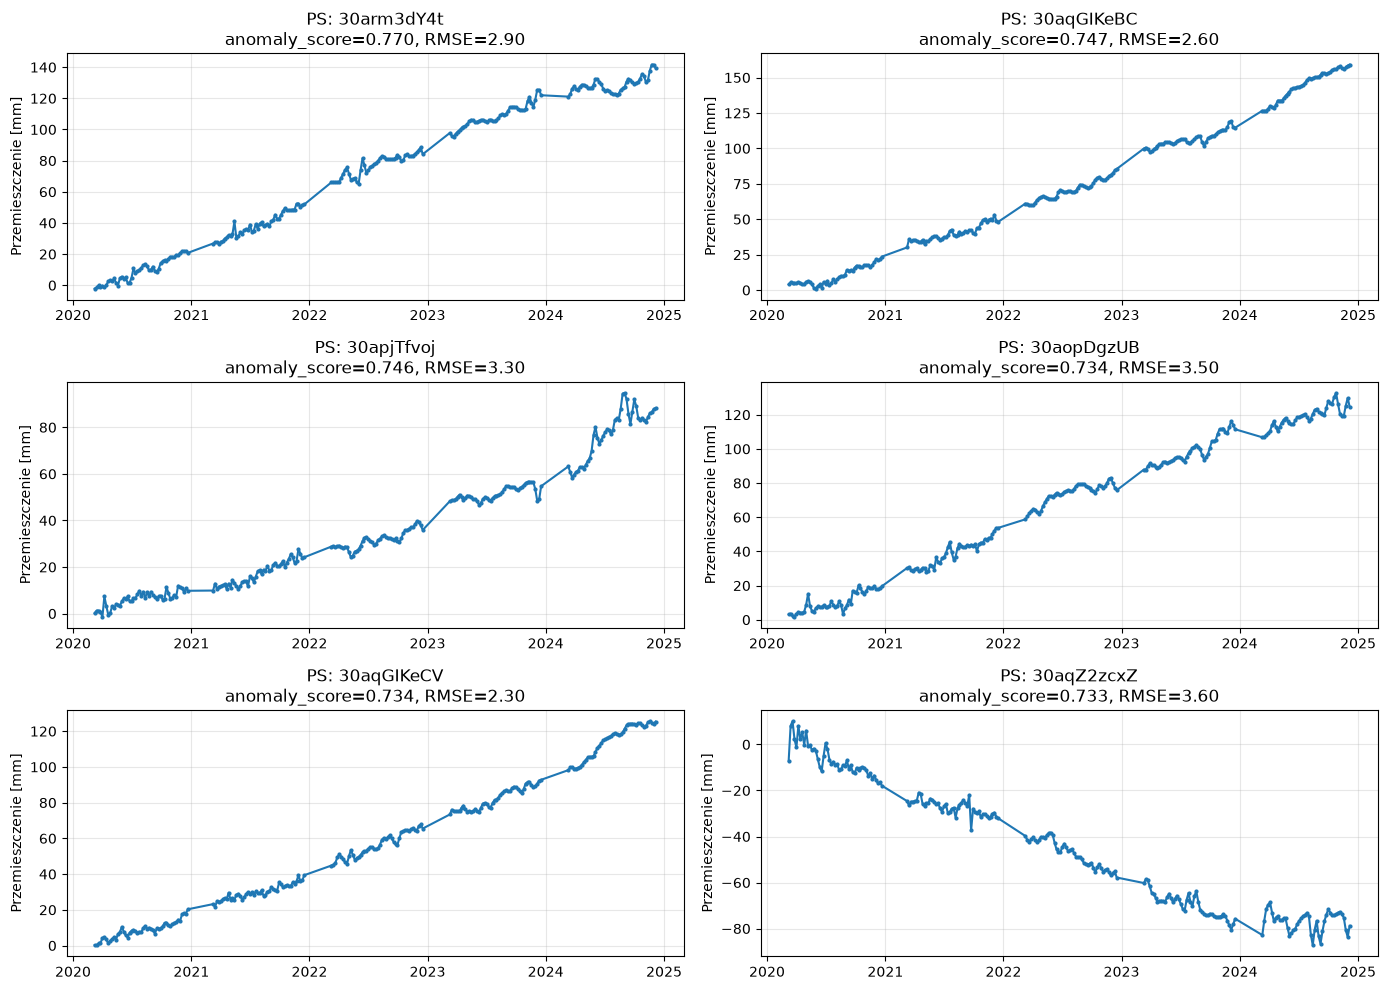

In [19]:
### Kontrola szeregów czasowych punktów o najwyższym wyniku nietypowości

top_anomalies = df.nlargest(6, "anomaly_score")

fig, axes = plt.subplots(3, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, (_, row) in zip(axes, top_anomalies.iterrows()):

    y = row[date_cols].astype(float).values

    ax.plot(dates, y, marker="o", markersize=2)

    ax.set_title(
        f"PS: {row['pid']}\n"
        f"anomaly_score={row['anomaly_score']:.3f}, "
        f"RMSE={row['rmse_ts']:.2f}"
    )

    ax.set_ylabel("Przemieszczenie [mm]")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [20]:
top20_model = df.nlargest(20, "anomaly_score")
top20_velocity = df.nsmallest(20, "mean_velocity")

model_ids = set(top20_model["pid"])
velocity_ids = set(top20_velocity["pid"])

common = model_ids & velocity_ids

print("Wspólne PS w TOP20:", len(common), "/ 20")
print("Udział wspólnych:",
      round(len(common) / 20 * 100, 1), "%")

Wspólne PS w TOP20: 2 / 20
Udział wspólnych: 10.0 %


### Wnioski z kontroli

1. **RMSE:** korelacja `anomaly_score` z `rmse_ts` wynosi 0,56, czyli jest umiarkowana. Część punktów jest wskazywana także dlatego, że ich szereg jest bardziej zaszumiony, ale RMSE rośnie też naturalnie przy dużych i nieliniowych przemieszczeniach.
2. **Szeregi czasowe:** sześć najbardziej nietypowych PS ma gładkie, wyraźne trendy rzędu 80–160 mm w ciągu niespełna 5 lat. Rozrzut wokół modelu (RMSE 2,3–3,6 mm) jest mały w porównaniu z amplitudą ruchu — to rzeczywiste, długotrwałe przemieszczenia, a nie szum.
3. **Nie tylko najszybszy ruch:** tylko 2 z 20 PS o najwyższym `anomaly_score` należą do 20 PS o najbardziej ujemnym `mean_velocity`. Model wskazuje punkty poruszające się w obu kierunkach oraz punkty ze zmianą tempa w ostatnim roku, a nie po prostu najmniejsze wartości `mean_velocity`.

# ETAP 5 — K-means: typowe rodzaje zachowania

> **Jakie grupy podobnych zachowań deformacyjnych występują w zbiorze?**

In [21]:
# Dokładnie te same punkty co w Isolation Forest; K-means wymaga standaryzacji.
mask_kmeans = mask_model
X_kmeans = df.loc[mask_kmeans, model_features].copy()
print('Liczba wszystkich PS:', len(df))
print('PS wykorzystane przez K-means:', len(X_kmeans))
print('PS pominięte z powodu braków:', (~mask_kmeans).sum())
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_kmeans)
print('Rozmiar danych po skalowaniu:', X_scaled.shape)

Liczba wszystkich PS: 3977
PS wykorzystane przez K-means: 3977
PS pominięte z powodu braków: 0
Rozmiar danych po skalowaniu: (3977, 3)


## Dobór liczby klastrów

Sprawdzamy `k = 2...8`.

- **Inertia / elbow** — szukamy miejsca, po którym dodawanie kolejnych klastrów daje coraz mniejszą poprawę.
- **Silhouette score** — wyższa wartość oznacza lepsze rozdzielenie grup.

Nie wybieramy `k` mechanicznie. Oprócz wykresów klastry powinny mieć sens interpretacyjny.


In [22]:
ks = range(2, min(8, len(X_scaled)-1) + 1)
inertias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    # Próbka ogranicza bardzo wysokie koszty obliczeniowe Silhouette dla dużego miasta.
    score = silhouette_score(X_scaled, labels,
                             sample_size=min(2000, len(X_scaled)), random_state=42)
    silhouettes.append(score)
results_k = pd.DataFrame({'k': list(ks), 'inertia': inertias, 'silhouette': silhouettes})
display(results_k.round(3))

,k,inertia,silhouette
0,2,9230.317,0.427
1,3,7466.976,0.427
2,4,6181.113,0.345
3,5,5423.850,0.347
4,6,4891.745,0.231
5,7,4511.513,0.236
6,8,4184.297,0.242


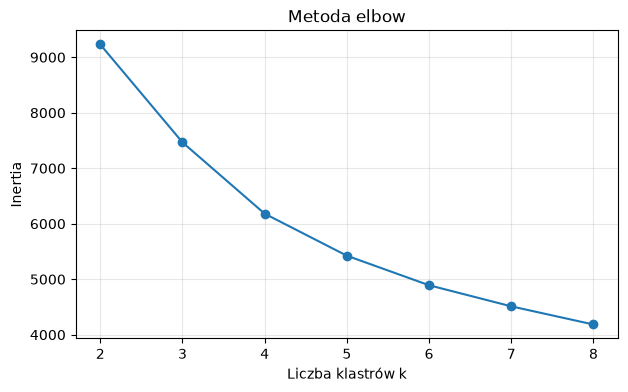

In [23]:
plt.figure(figsize=(7, 4))
plt.plot(results_k["k"], results_k["inertia"], marker="o")
plt.xlabel("Liczba klastrów k")
plt.ylabel("Inertia")
plt.title("Metoda elbow")
plt.grid(alpha=0.3)
plt.show()


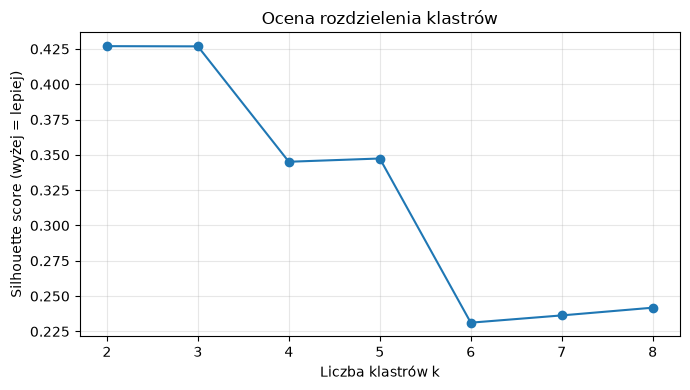

Najlepsze k wg Silhouette = 2
Sprawdź również załamanie wykresu elbow i sens interpretacyjny klastrów.


In [24]:
plt.figure(figsize=(7, 4))
plt.plot(results_k['k'], results_k['silhouette'], marker='o')
plt.xlabel('Liczba klastrów k')
plt.ylabel('Silhouette score (wyżej = lepiej)')
plt.title('Ocena rozdzielenia klastrów')
plt.xticks(results_k['k'])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
k_silhouette = int(results_k.loc[results_k['silhouette'].idxmax(), 'k'])
print('Najlepsze k wg Silhouette =', k_silhouette)
print('Sprawdź również załamanie wykresu elbow i sens interpretacyjny klastrów.')

In [25]:
# W tabeli k=2 i k=3 mają niemal identyczny silhouette (liczony na próbie 2000 PS),
# dlatego sprawdzamy oba warianty na pełnym zbiorze i oglądamy podział dla k=3.
for k in [2, 3]:
    labels_k = KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(X_scaled)
    print(f'k={k}: silhouette (pełny zbiór) = {silhouette_score(X_scaled, labels_k):.4f}')

labels_k3 = KMeans(n_clusters=3, n_init=20, random_state=42).fit_predict(X_scaled)
k3_summary = (
    df.loc[mask_kmeans, model_features]
    .assign(k3=labels_k3)
    .groupby('k3')
    .agg(n_PS=('mean_velocity', 'size'),
         mean_velocity=('mean_velocity', 'median'),
         acceleration=('acceleration', 'median'),
         trend_change=('trend_change', 'median'))
    .round(2)
)
k3_summary

k=2: silhouette (pełny zbiór) = 0.4226


k=3: silhouette (pełny zbiór) = 0.4251


,n_PS,mean_velocity,acceleration,trend_change
k3,,,,
0,339,0.7,1.40,7.00
1,3168,-0.1,0.02,-0.03
2,470,0.8,-1.12,-4.29


### Wybór `k`

| k | inertia | silhouette (próba 2000 PS) |
|---|---|---|
| 2 | 9230 | 0,427 |
| 3 | 7467 | 0,427 |
| 4 | 6181 | 0,345 |
| 5 | 5424 | 0,347 |
| 6–8 | 4892–4184 | 0,23–0,24 |

- **Silhouette** jest wyraźnie najwyższy dla k = 2 i k = 3 (≈ 0,43); od k = 4 spada do ≤ 0,35. Różnica między k = 2 a k = 3 jest pomijalna (0,4270 vs 0,4268 na próbie, 0,4226 vs 0,4251 na pełnym zbiorze), więc sam silhouette nie rozstrzyga.
- **Elbow:** inercja spada łagodnie (2→3: −19%, 3→4: −17%, 4→5: −12%), bez wyraźnego „łokcia”.
- **Interpretacja:** k = 3 dzieli punkty na stabilne (3168 PS), z dodatnią zmianą trendu w ostatnim roku (339 PS) i z ujemną zmianą trendu (470 PS). Przy k = 2 punkty z ujemną zmianą trendu trafiają do jednego klastra razem ze stabilnymi, a drugi klaster zbiera punkty z dodatnią zmianą trendu.

Wybieramy **k = 2**: przy praktycznie równym silhouette prostszy podział jest łatwiejszy do interpretacji, a oba klastry wyraźnie różnią się charakterystyką przemieszczeń (patrz niżej). Wariant k = 3 traktujemy jako uzupełnienie — dodatkowo wydziela 470 PS, w których trend w ostatnim roku przesunął się w stronę wartości ujemnych.

In [26]:
# Wartość sugerowana przez Silhouette; po sprawdzeniu elbow i charakterystyki grup
# można świadomie zmienić tę liczbę i zapisać uzasadnienie w sprawozdaniu.
k_final = k_silhouette
kmeans = KMeans(n_clusters=k_final, n_init=20, random_state=42)
labels_final = kmeans.fit_predict(X_scaled)
df['cluster'] = pd.NA
df.loc[mask_kmeans, 'cluster'] = labels_final
df['cluster'] = df['cluster'].astype('Int64')
print('Wybrano k =', k_final)
print('Liczebność klastrów:')
print(df['cluster'].value_counts(dropna=False).sort_index())

Wybrano k = 2
Liczebność klastrów:
cluster
0    3405
1     572
Name: count, dtype: Int64


C:\Users\hubi7\AppData\Local\Temp\ipykernel_31040\1688918714.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['cluster'] = pd.NA


## Charakterystyka klastrów

Po tej analizie można nadać klastrom opisowe nazwy, np. „regularne osiadanie” czy „zmienne tempo”, jeśli dane rzeczywiście to pokazują.


In [27]:
print("Liczebność klastrów:")
print(df["cluster"].value_counts().sort_index())

cluster_summary = (
    df.groupby("cluster")[model_features + ["rmse_ts", "anomaly_score"]]
      .median()
      .round(3)
)

cluster_summary


Liczebność klastrów:
cluster
0    3405
1     572
Name: count, dtype: Int64


,mean_velocity,acceleration,trend_change,rmse_ts,anomaly_score
cluster,,,,,
0,-0.10,-0.06,-0.402,1.1,0.366
1,0.15,1.02,4.745,2.0,0.489


### Interpretacja klastrów

| | klaster 0 | klaster 1 |
|---|---|---|
| liczba PS | 3405 (86%) | 572 (14%) |
| mediana `mean_velocity` [mm/rok] | −0,10 | 0,15 |
| mediana `acceleration` | −0,06 | 1,02 |
| mediana `trend_change` [mm/rok] | −0,40 | +4,75 |
| mediana `baseline_velocity` → `recent_velocity` [mm/rok] | −0,05 → −0,57 | −0,35 → +4,24 |
| mediana `annual_trend_std` [mm/rok] | 1,77 | 4,36 |
| mediana `rmse_ts` [mm] | 1,1 | 2,0 |

- **Klaster 0 — „stały charakter ruchu”.** Punkty stabilne oraz punkty poruszające się w stałym tempie, również szybko i w obu kierunkach. Tempo z ostatnich 12 miesięcy jest zwykle takie samo jak wcześniej (mediana `trend_change` ≈ 0). Trafiają tu też punkty, w których trend w ostatnim roku przesunął się w stronę wartości ujemnych.
- **Klaster 1 — „zmiana tempa w ostatnim roku”.** W ostatnich 12 miesiącach trend przesunął się w stronę wartości dodatnich (u 97% PS `trend_change` > 0): typowy punkt był wcześniej prawie stabilny, a w 2024 r. zaczął przemieszczać się na wschód; w klastrze są też punkty, które wcześniej szybko przemieszczały się na zachód i w ostatnim roku zwolniły. Klaster ma dodatnie przyspieszenie, dwa razy większą zmienność trendów rocznych i wyższy RMSE — część zmian może więc być szumem, dlatego oglądamy szeregi czasowe.

Średnia prędkość `mean_velocity` prawie nie różni klastrów (mediany ≈ 0): podział K-means wynika głównie ze **zmiany trendu i przyspieszenia**, a nie z samej prędkości.

## PCA — wizualizacja klastrów w dwóch wymiarach

PCA służy tylko do pokazania wielowymiarowych danych na płaszczyźnie. Kompresuje informację zawartą w wielu cechach do dwóch nowych wymiarów, dzięki czemu możemy zwizualizować wielowymiarowe dane na płaszczyźnie.



Wyjaśniona wariancja PC1 + PC2: 86.1 %


C:\Users\hubi7\AppData\Local\Temp\ipykernel_31040\2966130753.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["PC1"] = np.nan
C:\Users\hubi7\AppData\Local\Temp\ipykernel_31040\2966130753.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["PC2"] = np.nan


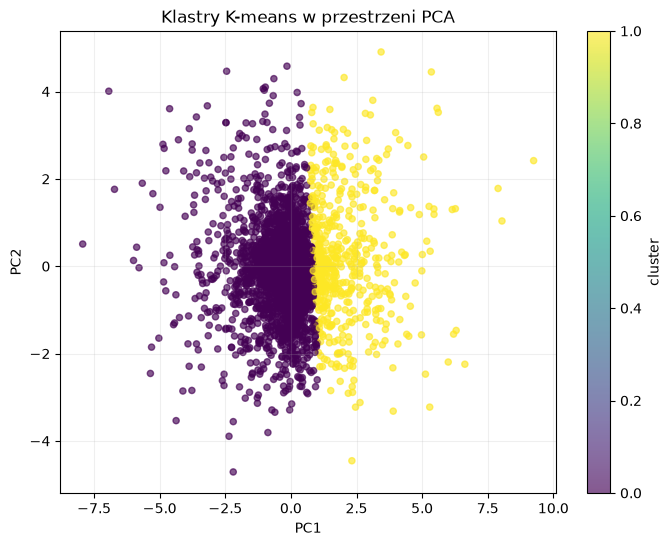

In [28]:
# PCA wykonujemy na tych samych PS,
# które zostały wykorzystane w K-means

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Tworzymy puste kolumny dla wszystkich PS
df["PC1"] = np.nan
df["PC2"] = np.nan

# Wyniki PCA przypisujemy tylko punktom,
# które uczestniczyły w K-means
df.loc[mask_kmeans, "PC1"] = X_pca[:, 0]
df.loc[mask_kmeans, "PC2"] = X_pca[:, 1]

print(
    "Wyjaśniona wariancja PC1 + PC2:",
    round(
        pca.explained_variance_ratio_.sum() * 100,
        1
    ),
    "%"
)

# Do wykresu bierzemy tylko PS posiadające wynik PCA i klaster
df_pca = df.loc[mask_kmeans].copy()

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    df_pca["PC1"],
    df_pca["PC2"],
    c=df_pca["cluster"].astype(int),
    alpha=0.65,
    s=20
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Klastry K-means w przestrzeni PCA")

plt.colorbar(
    scatter,
    label="cluster"
)

plt.grid(alpha=0.2)
plt.show()

Dwie pierwsze składowe PCA wyjaśniają 86,1% zmienności. Klastry rozdzielają się wzdłuż PC1, a granica między nimi jest ostra, bo K-means dzieli jedną ciągłą chmurę punktów, a nie dwie wyraźnie oddzielone grupy. Klastry należy więc traktować jako typy zachowania, a nie odrębne populacje punktów.

## Przykładowe szeregi z każdego klastra


C:\Users\hubi7\AppData\Local\Temp\ipykernel_31040\1470408518.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['centroid_distance'] = np.nan


,pid,typ,cluster,mean_velocity,trend_change,anomaly_score,rmse_ts
0,30anlaNYke,reprezentant klastra 0,0,-0.9,-0.752727,0.341836,0.6
1,30apHLgSdy,reprezentant klastra 1,1,1.2,6.293560,0.466349,2.3
2,30arm3dY4t,punkt anomalny,0,31.0,-21.427843,0.770424,2.9
3,30aqGIKeBC,punkt anomalny,1,33.6,14.706258,0.746693,2.6
4,30apjTfvoj,punkt anomalny,1,17.6,27.548305,0.746233,3.3


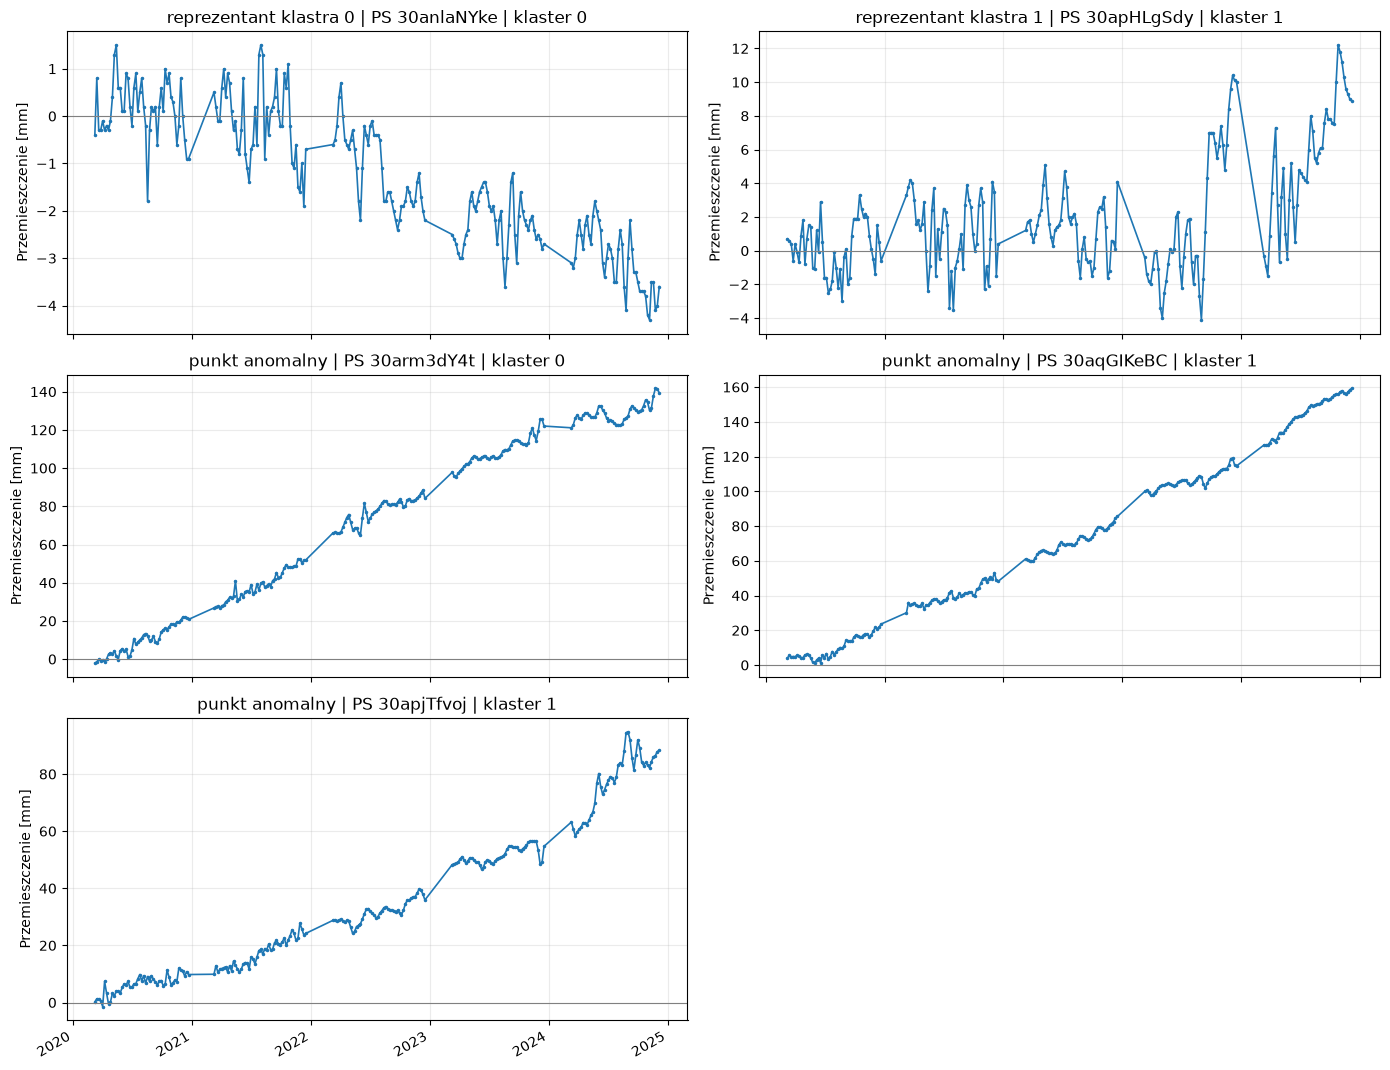

In [29]:
# Reprezentant klastra = punkt o najmniejszej odległości do centroidu (zwykle bez anomalii).
centroid_distances = kmeans.transform(X_scaled)[np.arange(len(X_scaled)), labels_final]
df['centroid_distance'] = np.nan
df.loc[mask_kmeans, 'centroid_distance'] = centroid_distances
chosen = []
for cid in sorted(df.loc[mask_kmeans, 'cluster'].dropna().unique()):
    group = df[(df['cluster'] == cid) & df['analysis_valid']]
    regular = group.loc[~group['anomaly']]
    pool = regular if not regular.empty else group
    row = pool.nsmallest(1, 'centroid_distance').iloc[0]
    chosen.append({'pid': row['pid'], 'typ': f'reprezentant klastra {cid}'})

for _, row in df.loc[df['anomaly']].nlargest(3, 'anomaly_score').iterrows():
    chosen.append({'pid': row['pid'], 'typ': 'punkt anomalny'})

selected_ps = pd.DataFrame(chosen).drop_duplicates('pid')
selected_ps = selected_ps.merge(df[['pid','cluster','mean_velocity','trend_change','anomaly_score','rmse_ts']], on='pid', how='left')
selected_ps.to_csv(DATA_DIR/'EGMS_Jastrzebie_przykladowe_PS.csv', index=False)
display(selected_ps)

n = len(selected_ps)
fig, axes = plt.subplots((n+1)//2, 2, figsize=(14, 3.6*((n+1)//2)), squeeze=False)
for ax, (_, item) in zip(axes.flat, selected_ps.iterrows()):
    row = df.loc[df['pid'] == item['pid']].iloc[0]
    y = row[date_cols].astype(float).to_numpy()
    ax.plot(dates, y, marker='.', linewidth=1.2, markersize=3)
    ax.axhline(0, color='gray', linewidth=0.8)
    ax.set_title(f"{item['typ']} | PS {row['pid']} | klaster {row['cluster']}")
    ax.set_ylabel('Przemieszczenie [mm]')
    ax.grid(alpha=0.25)
for ax in axes.flat[n:]:
    ax.axis('off')
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig(FIG_DIR/'EGMS_Jastrzebie_przykladowe_szeregi.png', dpi=220, bbox_inches='tight')
plt.show()

### Interpretacja szeregów czasowych

| PS | rola | przebieg |
|---|---|---|
| `30anlaNYke` | reprezentant klastra 0 | powolny, prawie liniowy ruch ok. −4 mm w 5 lat (−0,9 mm/rok) z szumem ±1 mm — punkt praktycznie stabilny |
| `30apHLgSdy` | reprezentant klastra 1 | do końca 2023 r. wahania 0–4 mm wokół stałego poziomu, w 2024 r. wzrost do 8–12 mm (`trend_change` +6,3 mm/rok) — typowy obraz klastra 1, ale zmiana jest porównywalna z szumem |
| `30arm3dY4t` | anomalia, klaster 0 | stały, liniowy ruch ok. +31 mm/rok, łącznie ok. 140 mm; w ostatnim roku wyraźne spowolnienie (`trend_change` −21 mm/rok) |
| `30aqGIKeBC` | anomalia, klaster 1 | najbardziej regularny, szybki ruch: +34 mm/rok, ok. 160 mm w 5 lat; w ostatnim roku jeszcze szybszy (`trend_change` +15 mm/rok) |
| `30apjTfvoj` | anomalia, klaster 1 | ruch przyspieszający: ok. 10 mm/rok w latach 2020–2021, potem szybciej, a w 2024 r. przyrost ok. 30 mm w kilka miesięcy (`trend_change` +27,5 mm/rok — najwięcej w całym zbiorze) |

**Różnice:** reprezentanci klastrów zmieniają położenie o pojedyncze milimetry, a ich przebieg jest zdominowany przez szum. Punkty anomalne przemieszczają się o rząd wielkości więcej (90–160 mm), a ich szeregi są gładkie — to rzeczywisty, długotrwały ruch terenu. Anomalie różnią się też kształtem przebiegu: ruch hamujący (`30arm3dY4t`), ruch stały z przyspieszeniem w ostatnim roku (`30aqGIKeBC`) i ruch wyraźnie przyspieszający (`30apjTfvoj`).

# ETAP 6 — Zestawienie wyników Isolation Forest i K-means

Obie metody opisują inne aspekty danych:

- `anomaly_score` — **jak nietypowy** jest PS,
- `cluster` — **do jakiego typu zachowania** jest najbardziej podobny.

Sprawdzamy więc, czy nietypowe PS koncentrują się w określonych klastrach.


In [30]:
cluster_model_summary = (
    df.groupby("cluster")
    .agg(
        n_PS=("pid", "count"),
        median_velocity=("mean_velocity", "median"),
        median_acceleration=("acceleration", "median"),
        median_trend_change=("trend_change", "median"),
        median_anomaly_score=("anomaly_score", "median"),
        max_anomaly_score=("anomaly_score", "max"),
        median_rmse=("rmse_ts", "median")
    )
    .round(3)
)

cluster_model_summary

,n_PS,median_velocity,median_acceleration,median_trend_change,median_anomaly_score,max_anomaly_score,median_rmse
cluster,,,,,,,
0,3405,-0.10,-0.06,-0.402,0.366,0.770,1.1
1,572,0.15,1.02,4.745,0.489,0.747,2.0


In [31]:
cluster_anomalies = df.groupby("cluster").agg(
    n_PS=("pid", "count"),
    n_anomalies=("anomaly", "sum"),
    median_anomaly_score=("anomaly_score", "median")
)

cluster_anomalies["percent_anomalies"] = (
    cluster_anomalies["n_anomalies"]
    / cluster_anomalies["n_PS"]
    * 100
).round(1)

cluster_anomalies

,n_PS,n_anomalies,median_anomaly_score,percent_anomalies
cluster,,,,
0,3405,103,0.365887,3.0
1,572,96,0.489385,16.8


**Wniosek:** anomalie nie rozkładają się równomiernie między klastrami. Klaster 1 obejmuje tylko 14% PS, ale zawiera 96 ze 199 anomalii (48%) — odsetek anomalii jest w nim 5,6 razy wyższy niż w klastrze 0 (16,8% vs 3,0%). Anomalie w obu klastrach mają inny charakter:
- w klastrze 0 to głównie **szybki ruch w stałym tempie** (mediana |`mean_velocity`| 17,5 mm/rok, u 78% powyżej 10 mm/rok); tu jest też najbardziej nietypowy punkt (`anomaly_score` 0,770),
- w klastrze 1 to głównie **silna zmiana tempa w ostatnim roku** (mediana |`trend_change`| 11,9 mm/rok, u 61% powyżej 10 mm/rok).

## Mapa robocza punktów PS

To przegląd przestrzenny wystarczy mapa punktowa `easting/northing`. Do mapy końcowej użyj QGIS, zachowując CRS zgodny z wejściowym EGMS. W notebooku wszystkie anomalie oznaczamy na czerwono, a klaster kolorem.

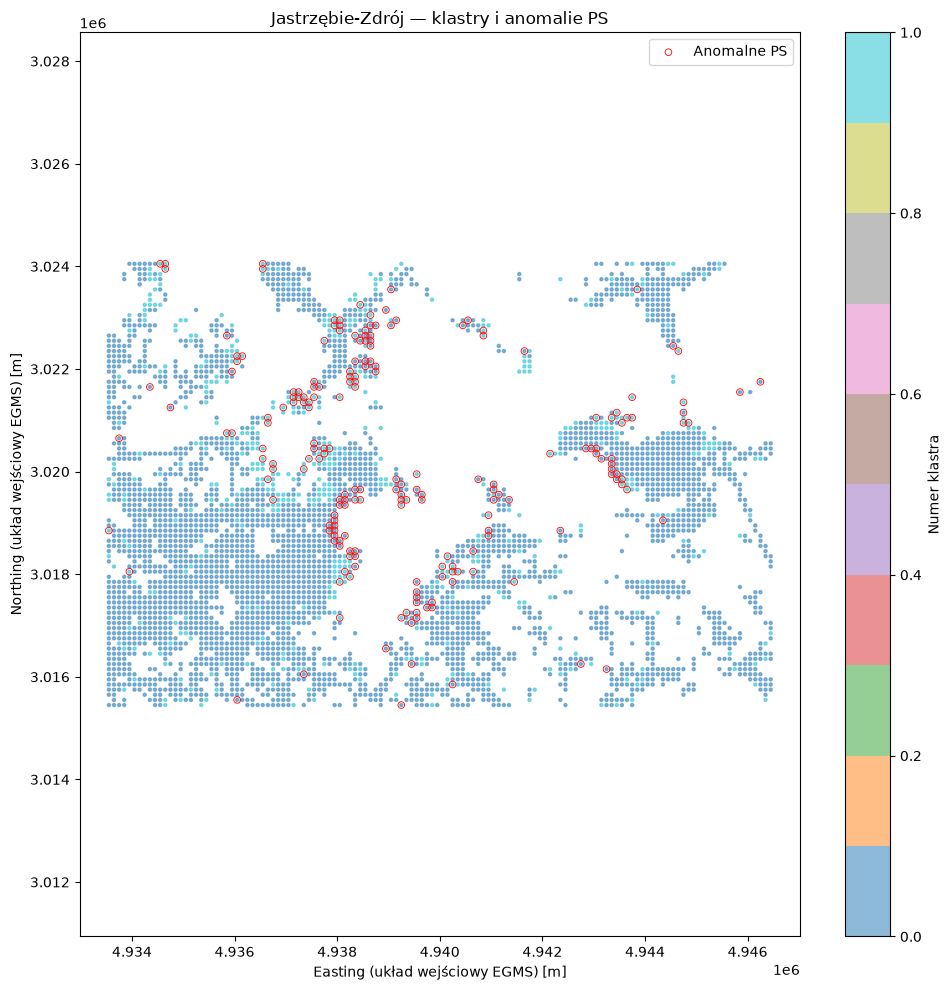

In [32]:
# Mapa robocza (bez podkładu). Do końcowego opracowania użyj QGIS.
map_df = df.loc[df['cluster'].notna()].copy()
map_sample = map_df.sample(n=min(25000,len(map_df)), random_state=42)
fig, ax = plt.subplots(figsize=(10, 10))
sc = ax.scatter(map_sample['easting'],map_sample['northing'],
                c=map_sample['cluster'].astype(int),cmap='tab10',
                s=5,alpha=0.5,rasterized=True)
flagged = map_df.loc[map_df['anomaly']]
ax.scatter(flagged['easting'],flagged['northing'],
           facecolors='none',edgecolors='red',s=23,linewidths=0.6,
           label='Anomalne PS')
ax.set_aspect('equal', adjustable='datalim')
ax.set_xlabel('Easting (układ wejściowy EGMS) [m]')
ax.set_ylabel('Northing (układ wejściowy EGMS) [m]')
ax.set_title('Jastrzębie-Zdrój — klastry i anomalie PS')
fig.colorbar(sc,ax=ax,label='Numer klastra')
ax.legend(loc='best')
plt.tight_layout()
plt.savefig(FIG_DIR/'EGMS_Jastrzebie_mapa_PS.png',dpi=220,bbox_inches='tight')
plt.show()

## Czy anomalie tworzą skupiska przestrzenne?

Sprawdzamy, jak często anomalny PS ma w promieniu 150 m (sąsiednie oczko siatki 100 m, także po skosie) inny anomalny PS, i porównujemy to z losowo wybranymi 199 PS (999 losowań — test Monte Carlo). Losujemy spośród istniejących PS, więc test uwzględnia nierównomierne rozmieszczenie punktów. Następnie łączymy sąsiadujące anomalie w grupy (DBSCAN, `eps` = 150 m, `min_samples` = 1) i numerujemy je od największej.

In [33]:
# Czy anomalie leżą bliżej siebie, niż wynikałoby z przypadku?
# Porównujemy udział anomalii mających inną anomalię w promieniu 150 m
# z tym samym udziałem dla losowo wybranych PS (test Monte Carlo).
from scipy.spatial import cKDTree
from sklearn.cluster import DBSCAN

RADIUS = 150  # sąsiednie oczka siatki 100 m, także po skosie (141 m)

anom = df.loc[df['anomaly']].copy()
xy_all = df[['easting', 'northing']].to_numpy()
xy_anom = anom[['easting', 'northing']].to_numpy()

def share_with_neighbour(points, radius=RADIUS):
    d, _ = cKDTree(points).query(points, k=2)
    return (d[:, 1] <= radius).mean()

observed = share_with_neighbour(xy_anom)
rng = np.random.default_rng(42)
simulated = np.array([
    share_with_neighbour(xy_all[rng.choice(len(xy_all), len(xy_anom), replace=False)])
    for _ in range(999)
])
p_value = ((simulated >= observed).sum() + 1) / (len(simulated) + 1)
print(f'Anomalie z inną anomalią w promieniu {RADIUS} m: {observed * 100:.1f}%')
print(f'To samo dla losowo wybranych PS (średnio):      {simulated.mean() * 100:.1f}%')
print(f'p-value (999 losowań): {p_value:.3f}')

# Grupy anomalii: DBSCAN z min_samples=1 łączy anomalie oddalone o <= 150 m.
anom['anomaly_group'] = DBSCAN(eps=RADIUS, min_samples=1).fit_predict(xy_anom)
groups = (
    anom.groupby('anomaly_group')
    .agg(n_PS=('pid', 'count'),
         easting=('easting', 'mean'),
         northing=('northing', 'mean'),
         median_velocity=('mean_velocity', 'median'),
         median_trend_change=('trend_change', 'median'),
         share_cluster_1=('cluster', lambda s: (s == 1).mean()))
    .reset_index()
    .sort_values(['n_PS', 'anomaly_group'], ascending=[False, True])
)
groups['nr_skupiska'] = np.arange(1, len(groups) + 1)
big_groups = groups.loc[groups['n_PS'] >= 5].set_index('nr_skupiska')

sizes = anom['anomaly_group'].value_counts()
print('\nGrup anomalii:', len(groups))
print('Pojedyncze anomalie (bez sąsiedniej anomalii):', int((sizes == 1).sum()))
print('Skupiska >= 5 anomalii:', len(big_groups), '| anomalii w nich:', int(big_groups['n_PS'].sum()))
big_groups.drop(columns='anomaly_group').round(2)

Anomalie z inną anomalią w promieniu 150 m: 72.4%
To samo dla losowo wybranych PS (średnio):      25.4%
p-value (999 losowań): 0.001

Grup anomalii: 93
Pojedyncze anomalie (bez sąsiedniej anomalii): 55
Skupiska >= 5 anomalii: 10 | anomalii w nich: 73


,n_PS,easting,northing,median_velocity,median_trend_change,share_cluster_1
nr_skupiska,,,,,,
1,11,4937968.18,3018831.82,20.70,-6.01,0.0
2,10,4937310.00,3021420.00,-16.90,13.72,1.0
3,10,4938580.00,3022650.00,23.65,4.84,0.3
4,9,4943450.00,3019938.89,-22.40,-5.32,0.33
5,7,4939235.71,3019578.57,24.40,1.39,0.43
6,6,4938300.00,3021800.00,9.20,15.62,1.0
7,5,4943010.00,3020390.00,-15.00,-5.98,0.0
8,5,4938110.00,3019430.00,14.60,-8.91,0.0
9,5,4938650.00,3022070.00,13.60,-11.46,0.0


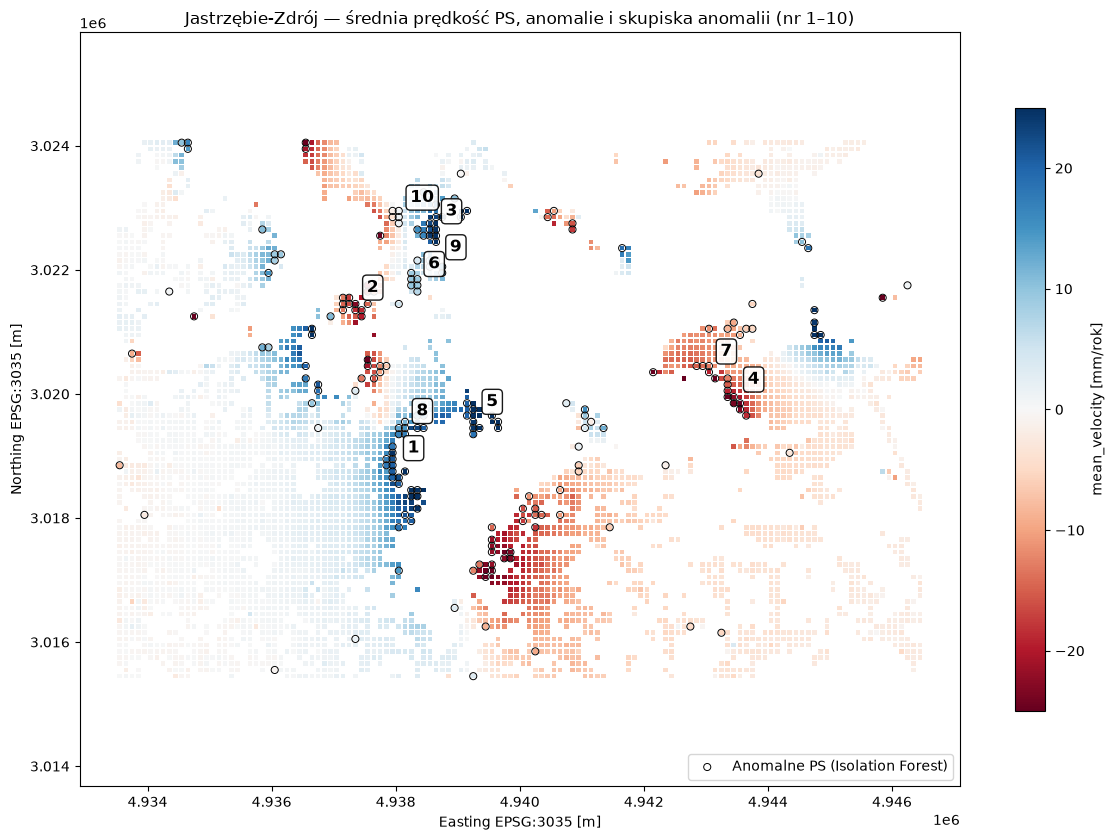

In [34]:
# Mapa prędkości z zaznaczonymi anomaliami i numerami skupisk.
# Skala kolorów jest symetryczna: przy składowej wschód–zachód niebieski = ruch na wschód, czerwony = na zachód.
fig, ax = plt.subplots(figsize=(12, 8.5))
sc = ax.scatter(df['easting'], df['northing'], c=df['mean_velocity'], cmap='RdBu',
                vmin=-25, vmax=25, s=11, marker='s', linewidths=0)
ax.scatter(anom['easting'], anom['northing'], facecolors='none', edgecolors='black',
           s=26, linewidths=0.7, label='Anomalne PS (Isolation Forest)')
for nr, g in big_groups.iterrows():
    ax.annotate(str(nr), (g['easting'], g['northing']), xytext=(10, 10), textcoords='offset points',
                fontsize=12, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='black', alpha=0.9))
ax.set_aspect('equal', adjustable='datalim')
ax.set_xlabel('Easting EPSG:3035 [m]')
ax.set_ylabel('Northing EPSG:3035 [m]')
ax.set_title('Jastrzębie-Zdrój — średnia prędkość PS, anomalie i skupiska anomalii (nr 1–10)')
fig.colorbar(sc, ax=ax, shrink=0.8, label='mean_velocity [mm/rok]')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(FIG_DIR / 'EGMS_Jastrzebie_skupiska_anomalii.png', dpi=200, bbox_inches='tight')
plt.show()

### Wnioski — rozkład przestrzenny anomalii

- **Anomalie tworzą skupiska.** 72,4% anomalii ma inną anomalię w promieniu 150 m, a dla losowo wybranych PS jest to średnio 25,4% (p = 0,001). Tylko 55 ze 199 anomalii leży pojedynczo; 10 skupisk liczy co najmniej 5 PS (łącznie 73 anomalie).
- **Strefy ruchu.** Ruch na wschód (kolor niebieski) dominuje w zachodniej części obszaru, a ruch na zachód (czerwony) — w części południowo-wschodniej (rejon Bzia) i wschodniej (rejon Pniówka i Pawłowic). Między nimi leżą tereny bez PS (pola, lasy, tereny przemysłowe), a przemieszczenia skierowane są w ich stronę. To typowy obraz brzegów niecek osiadania nad eksploatowanymi pokładami: grunt na obrzeżach niecki przesuwa się poziomo w stronę jej środka.
- **Skupiska leżą na brzegach stref silnego ruchu**, gdzie prędkość szybko zmienia się na krótkim odcinku: skupiska 1, 5, 8 na wschodnim skraju strefy ruchu na wschód (od +15 do +25 mm/rok), skupiska 4 i 7 na zachodnim skraju strefy ruchu na zachód przy Pawłowicach (od −15 do −22 mm/rok), skupiska 2, 3, 6, 9, 10 w północnej części obszaru, gdzie sąsiadują strefy o przeciwnych kierunkach ruchu. Duże różnice prędkości poziomych na krótkim odcinku oznaczają rozciąganie lub ściskanie gruntu, które jest szczególnie niekorzystne dla zabudowy.
- **Skupiska a klastry.** Skupiska 2, 6 i 10 składają się wyłącznie z PS klastra 1 (mediana `trend_change` od +14 do +16 mm/rok) — ruch pojawił się lub wyraźnie zmienił tempo w 2024 r. Skupiska 1, 7, 8, 9 to wyłącznie PS klastra 0, czyli szybki ruch w stałym kierunku.

# ETAP 7 — Eksport do QGIS

Eksportujemy danych do QGIS.

In [35]:
export_cols = [
    'pid','easting','northing',
    'mean_velocity','acceleration','seasonality','rmse_ts',
    'trend','trend_R2','annual_trend_std',
    'baseline_velocity','recent_velocity','trend_change',
    'analysis_valid','anomaly_score','anomaly','cluster','centroid_distance'
]
missing_cols = [col for col in export_cols if col not in df.columns]
if missing_cols:
    raise ValueError(f'Brakujące kolumny przed eksportem: {missing_cols}')
df[export_cols].to_csv(OUTPUT_CSV, index=False)
print('Zapisano wyniki PS:', OUTPUT_CSV.resolve())

Zapisano wyniki PS: C:\Users\hubi7\Desktop\Uczelnia\Analiza i przetwarzanie danych przestrzennych\jz\EGMS_Jastrzebie_results.csv


# ETAP 8 — Wnioski

**1. Typy deformacji.** Analizowana składowa to ruch poziomy wschód–zachód z EGMS Ortho (plik `EGMS_L3_E49N30_100km_E_2020_2024_1.zip`). Na obszarze występują:
- tereny praktycznie stabilne — większość PS, zwłaszcza w zachodniej i południowej części miasta,
- rozległe strefy stałego ruchu poziomego o prędkościach do ±37 mm/rok — na wschód w zachodniej części obszaru i na zachód w części południowo-wschodniej i wschodniej; otaczają one tereny bez PS i najpewniej są brzegami niecek osiadania nad eksploatowanymi pokładami węgla,
- punkty, w których tempo ruchu zmieniło się w ostatnim roku (klaster 1, 14% PS).

**2. Anomalie.** Isolation Forest wskazał 199 PS (5%). Są to głównie rzeczywiste, gładkie przemieszczenia rzędu 80–160 mm w ciągu niespełna 5 lat oraz punkty z gwałtowną zmianą tempa w 2024 r. Korelacja z RMSE (0,56) pokazuje jednak, że część wyników może być zawyżona przez szum.

**3. Skupiska przestrzenne.** Anomalie tworzą skupiska (72% ma sąsiednią anomalię wobec 25% przy losowym wyborze, p = 0,001). 10 skupisk liczących co najmniej 5 PS leży na brzegach stref silnego ruchu, gdzie prędkość zmienia się najszybciej.

**4. Anomalie a klastry.** Anomalie występują w obu klastrach, ale w klastrze 1 są 5,6 razy częstsze (16,8% vs 3,0%). W klastrze 0 anomalie to głównie szybki ruch w stałym tempie, w klastrze 1 — silna zmiana tempa w ostatnim roku.

**5. Do dalszej analizy** warto wskazać przede wszystkim:
- skupisko 1 — wschodni skraj zwartej zabudowy centrum Jastrzębia-Zdroju, ruch ok. +21 mm/rok, najwięcej budynków z anomalnym PS (51),
- skupiska 2, 6 i 10 w północnej części obszaru — ruch, który pojawił się lub wyraźnie zmienił w 2024 r. (klaster 1),
- skupiska 4 i 7 — zachodni skraj Pawłowic, ruch na zachód od −15 do −22 mm/rok, który w ostatnim roku jeszcze przyspieszył.

Lista budynków powstaje w notebooku `EGMS_Jastrzebie_analiza_budynkow.ipynb` (plik `budynki_do_dalszej_analizy.csv`).

**Ograniczenia:** siatka 100 m (PS opisuje ruch terenu w otoczeniu, a nie konkretny budynek), tylko jedna składowa ruchu (w składowej wschód–zachód nie widać samego osiadania — do tego potrzebna byłaby składowa pionowa U), arbitralny próg 5% dla anomalii oraz wyniki K-means zależne od wyboru cech i liczby klastrów.